# MecâniQA — Entregável 3: Tunando o Meu Modelo

**Time:** Boa Vista
**Membros:** Alex Oliveira Santos, Alice Gomes Aragão, Ana Clara Ribeiro da Silva, Lorran Edley Matos Ribeiro, Rodrigo dos Anjos Lamartine

## Contexto

Na OAT 1 entendemos os dados e criamos baselines (Naive e Médias Móveis). Na OAT 2 avaliamos esses baselines com MAE, RMSE e MAPE, usamos validação temporal (`TimeSeriesSplit`) e criamos as features temporais (Lags e Rolling Window).

O baseline é apenas o piso. Nesta OAT 3 o desafio é **construir, otimizar e comparar modelos de Machine Learning** para reduzir o erro de previsão da demanda de **Trocas de Óleo** e **Manutenções de Motor**:

1. **Modelos clássicos de regressão** com hiperparâmetros padrão.
2. **Grid Search** integrado ao `TimeSeriesSplit`.
3. **Random Search** e o trade-off tempo × erro.
4. **Comparação rigorosa:** Baseline antigo × ML inicial × ML tunado, com MAE, RMSE e MAPE e gráfico sobreposto.

> **Regra de ouro do notebook:** o conjunto de teste (últimos 20% dos dias) só é usado no final, para medir o erro. Treino, seleção de modelo e busca de hiperparâmetros acontecem **exclusivamente no treino**, sempre respeitando a linha do tempo.

## 1. Importações e configurações

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

SEED = 42
ALVOS = ["Trocas_Oleo", "Manutencao_Motor"]
NOMES = {"Trocas_Oleo": "Trocas de Óleo", "Manutencao_Motor": "Manutenção de Motor"}
CORES = {"Real": "black", "Baseline": "#E8833A", "ML inicial": "#7F7F7F", "ML tunado": "#1F77B4"}

pd.set_option("display.max_columns", None)
pd.options.display.float_format = "{:.2f}".format
plt.rcParams.update({"figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

## 2. Dados: limpeza e features (pipeline das OAT 1 e 2)

Partimos do **dataset já limpo** e com as **features temporais** construídas nas etapas anteriores:

- Limpeza: valores negativos → `NaN` → interpolação temporal; outliers tratados por clipping (IQR).
- Features: Lags de 1, 7 e 30 dias e Rolling Mean de 7 dias (com `shift(1)`, para nunca olhar o dia atual).
- Os primeiros 30 dias são descartados (`NaN` gerado pelo Lag 30).

In [2]:
df_bruto = pd.read_excel("mecaniqa_dataset.xlsx")
df_bruto["Data"] = pd.to_datetime(df_bruto["Data"])
df_bruto = df_bruto.set_index("Data").sort_index().asfreq("D")

df_limpo = df_bruto.copy()
for alvo in ALVOS:
    df_limpo.loc[df_limpo[alvo] < 0, alvo] = np.nan              # negativos são inválidos
    df_limpo[alvo] = df_limpo[alvo].interpolate(method="time")   # ausentes e inválidos

    q1, q3 = df_limpo[alvo].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf, limite_sup = max(0, q1 - 1.5 * iqr), q3 + 1.5 * iqr
    df_limpo[alvo] = df_limpo[alvo].clip(lower=limite_inf, upper=limite_sup)

print("Formato do dataset limpo:", df_limpo.shape)
print("Período:", df_limpo.index.min().date(), "a", df_limpo.index.max().date())
print("Valores ausentes após a limpeza:", df_limpo.isna().sum().to_dict())

Formato do dataset limpo: (731, 2)
Período: 2024-01-01 a 2025-12-31
Valores ausentes após a limpeza: {'Trocas_Oleo': 0, 'Manutencao_Motor': 0}


In [3]:
LAGS = [1, 7, 30]
JANELA = 7

df_feat = df_limpo.copy()
for alvo in ALVOS:
    for lag in LAGS:
        df_feat[f"{alvo}_lag_{lag}"] = df_feat[alvo].shift(lag)
    # shift(1): a média da janela em t usa apenas t-7 ... t-1 (sem o próprio dia t)
    df_feat[f"{alvo}_rolling_mean_{JANELA}"] = (
        df_feat[alvo].rolling(window=JANELA, min_periods=JANELA).mean().shift(1)
    )

linhas_antes = len(df_feat)
df_feat = df_feat.dropna()
FEATURES = [c for c in df_feat.columns if c not in ALVOS]

print(f"Linhas descartadas (NaN do Lag 30): {linhas_antes - len(df_feat)}")
print(f"Linhas finais: {len(df_feat)} | Features usadas pelos modelos: {len(FEATURES)}")
df_feat.head()

Linhas descartadas (NaN do Lag 30): 30
Linhas finais: 701 | Features usadas pelos modelos: 8


,Trocas_Oleo,Manutencao_Motor,Trocas_Oleo_lag_1,Trocas_Oleo_lag_7,Trocas_Oleo_lag_30,Trocas_Oleo_rolling_mean_7,Manutencao_Motor_lag_1,Manutencao_Motor_lag_7,Manutencao_Motor_lag_30,Manutencao_Motor_rolling_mean_7
Data,,,,,,,,,,
2024-01-31,14.00,5.00,14.00,10.00,11.00,19.57,4.00,2.00,2.00,7.71
2024-02-01,21.00,13.00,14.00,13.00,9.00,20.14,5.00,10.00,4.00,8.14
2024-02-02,31.00,12.00,21.00,30.00,12.00,21.29,13.00,12.00,1.00,8.57
2024-02-03,28.00,13.00,31.00,26.00,15.00,21.43,12.00,10.00,8.00,8.57
2024-02-04,34.00,12.00,28.00,31.00,25.00,21.71,13.00,10.00,10.00,9.00


## 3. A linha do tempo: divisão cronológica treino × teste

**Decisão da equipe:** a divisão será cronológica, sem embaralhar os dias: os primeiros 80% para treino e os 20% finais para teste. O `fit()` usa somente o treino, e o teste só entra no `predict()` para medir o erro. As features de lag e rolling usam `shift`, então cada linha só carrega informação do passado. O QA confirma isso com uma checagem automática.

Treino: 2024-01-31 a 2025-08-12  (560 dias)
Teste : 2025-08-13 a 2025-12-31  (141 dias)


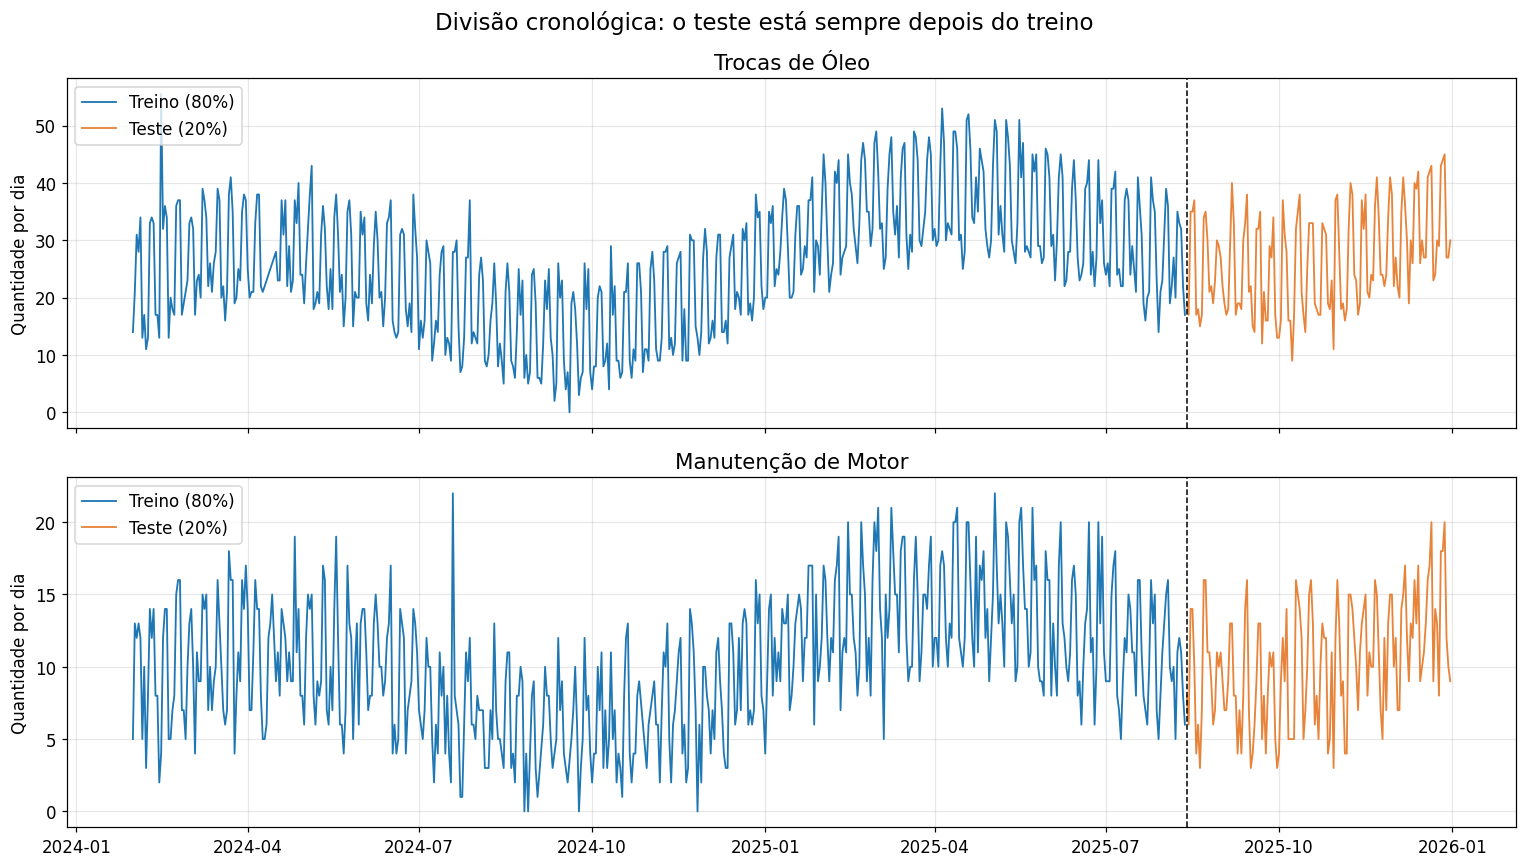

In [4]:
PROP_TREINO = 0.80
n_treino = int(len(df_feat) * PROP_TREINO)

treino, teste = df_feat.iloc[:n_treino], df_feat.iloc[n_treino:]
X_treino, X_teste = treino[FEATURES], teste[FEATURES]

print(f"Treino: {treino.index.min().date()} a {treino.index.max().date()}  ({len(treino)} dias)")
print(f"Teste : {teste.index.min().date()} a {teste.index.max().date()}  ({len(teste)} dias)")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, alvo in zip(axes, ALVOS):
    ax.plot(treino.index, treino[alvo], color="#1F77B4", lw=1.2, label="Treino (80%)")
    ax.plot(teste.index, teste[alvo], color="#E8833A", lw=1.2, label="Teste (20%)")
    ax.axvline(teste.index[0], color="black", ls="--", lw=1)
    ax.set_title(NOMES[alvo], fontsize=14)
    ax.set_ylabel("Quantidade por dia")
    ax.legend(loc="upper left")
fig.suptitle("Divisão cronológica: o teste está sempre depois do treino", fontsize=15)
fig.tight_layout()
plt.show()

### 3.1 QA anti-leakage

Critério do QA: provar que nenhuma informação do teste (nem do futuro) vazou para o treino ou para as features.

In [5]:
def qa_validar_sem_leakage():
    erros = []

    # 1) todo o treino vem ANTES de todo o teste, sem sobreposição
    if not treino.index.max() < teste.index.min():
        erros.append("Treino e teste se sobrepõem no tempo.")

    for alvo in ALVOS:
        # 2) lag_k deve ser exatamente o valor real de t-k
        for lag in LAGS:
            esperado = df_limpo[alvo].shift(lag).loc[df_feat.index]
            if not np.allclose(df_feat[f"{alvo}_lag_{lag}"], esperado):
                erros.append(f"{alvo}: lag_{lag} não corresponde a t-{lag}.")

        # 3) rolling_mean_7 em t = média de t-7 ... t-1 (sem t)
        idx = treino.index[-1]
        pos = df_limpo.index.get_loc(idx)
        manual = df_limpo[alvo].iloc[pos - JANELA: pos].mean()
        if not np.isclose(manual, df_feat.loc[idx, f"{alvo}_rolling_mean_{JANELA}"]):
            erros.append(f"{alvo}: a rolling mean parece incluir o dia atual.")

    # 4) a limpeza (interpolação/clipping) não alterou nenhum valor da janela de teste
    ajustados = (df_bruto.loc[teste.index, ALVOS] != df_limpo.loc[teste.index, ALVOS]).sum().sum()
    print(f"Valores ajustados pela limpeza dentro da janela de teste: {ajustados}")
    if ajustados > 0:
        erros.append("A limpeza alterou valores da janela de teste.")

    if erros:
        print("QA REPROVADO:")
        for e in erros:
            print(" -", e)
        return False
    print("QA APROVADO: treino anterior ao teste, features só com o passado e teste intacto.")
    return True


qa_validar_sem_leakage()

Valores ajustados pela limpeza dentro da janela de teste: 0
QA APROVADO: treino anterior ao teste, features só com o passado e teste intacto.


True

## 4. Motor de métricas e baselines antigos

Criamos aqui o **motor de métricas** que será usado em todo o notebook: ele calcula **MAE, RMSE e MAPE ao mesmo tempo** para qualquer conjunto de previsões. O MAPE considera apenas os dias com demanda diferente de zero (a divisão por zero não é definida), como na OAT 2.

O **Baseline Antigo** de cada variável é o melhor baseline da OAT 2 (Naive ou Média Móvel 7d). Para não "espiar" o teste, a escolha é feita pelo **MAE na janela de treino**.

In [6]:
def avaliar_metricas(y_real, y_previsto) -> dict:
    y_real = np.asarray(y_real, dtype=float)
    y_prev = np.asarray(y_previsto, dtype=float)
    mascara = y_real != 0
    return {
        "MAE": mean_absolute_error(y_real, y_prev),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_prev)),
        "MAPE (%)": mean_absolute_percentage_error(y_real[mascara], y_prev[mascara]) * 100,
    }


def avaliar_cenarios(y_real, previsoes: dict) -> pd.DataFrame:
    """Calcula MAE, RMSE e MAPE simultaneamente para vários cenários de previsão."""
    return pd.DataFrame({nome: avaliar_metricas(y_real, prev) for nome, prev in previsoes.items()}).T


def previsao_naive(serie):
    return serie.shift(1)


def previsao_media_movel(serie, janela=7):
    return serie.rolling(window=janela, min_periods=janela).mean().shift(1)


baselines, melhor_baseline = {}, {}
for alvo in ALVOS:
    serie = df_limpo[alvo]
    candidatos = {"Naive": previsao_naive(serie), "Média Móvel 7d": previsao_media_movel(serie, 7)}
    mae_treino = {n: avaliar_metricas(serie.loc[treino.index], p.loc[treino.index])["MAE"] for n, p in candidatos.items()}
    melhor_baseline[alvo] = min(mae_treino, key=mae_treino.get)
    baselines[alvo] = candidatos
    print(f"{NOMES[alvo]:<20} MAE no treino: " + " | ".join(f"{n}: {v:.2f}" for n, v in mae_treino.items())
          + f"  ->  Baseline antigo = {melhor_baseline[alvo]}")

Trocas de Óleo       MAE no treino: Naive: 6.70 | Média Móvel 7d: 7.37  ->  Baseline antigo = Naive
Manutenção de Motor  MAE no treino: Naive: 3.38 | Média Móvel 7d: 3.22  ->  Baseline antigo = Média Móvel 7d


## 5. Modelos clássicos de regressão (hiperparâmetros padrão)

**Decisão da equipe:** escolhemos o Random Forest e o Gradient Boosting, com a Árvore de Decisão e a Regressão Linear como referência. Modelos de árvores capturam padrões não lineares, como o pico de demanda no fim de semana e a tendência de crescimento da oficina, sem precisar transformar os dados. O Random Forest treina várias árvores e tira a média das previsões, o que reduz a variância. O Gradient Boosting treina árvores em sequência, e cada uma corrige o erro da anterior. A Regressão Linear serve de comparação simples.

**Pipeline básico:** `fit()` **somente** no treino e `predict()` no teste, com os hiperparâmetros **default** do scikit-learn.

In [7]:
def criar_modelos():
    return {
        "Regressão Linear": LinearRegression(),
        "Árvore de Decisão": DecisionTreeRegressor(random_state=SEED),
        "Random Forest": RandomForestRegressor(random_state=SEED),
        "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
    }


modelos_iniciais = {alvo: criar_modelos() for alvo in ALVOS}
previsoes_iniciais = {alvo: {} for alvo in ALVOS}

for alvo in ALVOS:
    for nome, modelo in modelos_iniciais[alvo].items():
        modelo.fit(X_treino, treino[alvo])                      # fit SOMENTE nos dados de treino
        previsoes_iniciais[alvo][nome] = pd.Series(modelo.predict(X_teste), index=teste.index)

for alvo in ALVOS:
    nome_base = f"Baseline antigo ({melhor_baseline[alvo]})"
    previsoes = {nome_base: baselines[alvo][melhor_baseline[alvo]].loc[teste.index], **previsoes_iniciais[alvo]}
    tabela = avaliar_cenarios(teste[alvo], previsoes)

    ref = tabela.iloc[0]
    tabela["Bate o baseline?"] = ["referência"] + [
        "SIM" if (r["RMSE"] < ref["RMSE"] and r["MAPE (%)"] < ref["MAPE (%)"]) else "não"
        for _, r in tabela.iloc[1:].iterrows()
    ]
    print(f"\n=== {NOMES[alvo]} — ML inicial (hiperparâmetros default) no conjunto de TESTE ===")
    print(tabela.to_string())


=== Trocas de Óleo — ML inicial (hiperparâmetros default) no conjunto de TESTE ===
                         MAE  RMSE  MAPE (%) Bate o baseline?
Baseline antigo (Naive) 6.48  8.92     26.80       referência
Regressão Linear        3.30  4.16     14.02              SIM
Árvore de Decisão       4.60  5.85     20.38              SIM
Random Forest           3.04  3.81     13.34              SIM
Gradient Boosting       3.18  4.00     13.70              SIM

=== Manutenção de Motor — ML inicial (hiperparâmetros default) no conjunto de TESTE ===
                                  MAE  RMSE  MAPE (%) Bate o baseline?
Baseline antigo (Média Móvel 7d) 3.23  3.82     41.05       referência
Regressão Linear                 2.06  2.42     26.96              SIM
Árvore de Decisão                3.02  3.90     38.37              não
Random Forest                    2.05  2.48     28.40              SIM
Gradient Boosting                2.10  2.49     28.45              SIM


O erro inicial (RMSE e MAPE) mostra se os modelos "crus" já batem os baselines. Quase todos batem: eles aprendem padrões (como o ritmo semanal e a tendência) que o baseline, que só repete ou suaviza o passado, não captura. A **Árvore de Decisão** isolada é a mais fraca, porque uma única árvore tende a decorar o treino; é por isso que conjuntos de árvores (Random Forest e Gradient Boosting) fazem mais sentido. A Regressão Linear é uma concorrente forte, porque a série é bem explicada por lags e sazonalidade semanal.

### 5.1 Escolhendo o modelo para o tuning (sem olhar o teste)

Entre os modelos com hiperparâmetros relevantes (Árvore, Random Forest e Gradient Boosting), escolhemos o melhor pela **validação cruzada temporal dentro do treino**. Assim o conjunto de teste continua intocado.

In [8]:
tscv = TimeSeriesSplit(n_splits=5)

candidatos_tuning = {
    "Árvore de Decisão": DecisionTreeRegressor(random_state=SEED),
    "Random Forest": RandomForestRegressor(random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
}

cv_inicial = {alvo: {} for alvo in ALVOS}
for alvo in ALVOS:
    for nome, modelo in candidatos_tuning.items():
        scores = cross_val_score(modelo, X_treino, treino[alvo], cv=tscv,
                                 scoring="neg_root_mean_squared_error", n_jobs=-1)
        cv_inicial[alvo][nome] = -scores.mean()

tabela_cv = pd.DataFrame(cv_inicial).rename(columns=NOMES)
tabela_cv.index.name = "RMSE na validação cruzada (treino)"
for alvo in ALVOS:
    print(f"{NOMES[alvo]:<20} modelo com menor RMSE na validação: {min(cv_inicial[alvo], key=cv_inicial[alvo].get)}")
tabela_cv

Trocas de Óleo       modelo com menor RMSE na validação: Random Forest
Manutenção de Motor  modelo com menor RMSE na validação: Random Forest


,Trocas de Óleo,Manutenção de Motor
RMSE na validação cruzada (treino),,
Árvore de Decisão,9.67,3.83
Random Forest,5.86,3.00
Gradient Boosting,7.46,3.56


## 6. Sintonia de hiperparâmetros: Grid Search com TimeSeriesSplit

**Decisão da equipe (espaço de busca):** vamos sintonizar o Random Forest, que teve o menor erro de validação entre os modelos de árvores (seção 5.1). Os hiperparâmetros são `n_estimators` em {50, 100, 200}, `max_depth` em {3, 5, 10, None} e `min_samples_leaf` em {1, 2, 4, 8}. Mais árvores estabilizam a média, e a profundidade e o tamanho mínimo das folhas controlam o risco de decorar o treino. São 48 combinações, ou 240 treinos com 5 folds, um custo razoável para 560 dias de treino.

**Decisão da equipe (proteção temporal):** com um K-Fold comum, os dias seriam embaralhados e o modelo treinaria com o futuro para prever o passado, o que dá um erro otimista. Com o `TimeSeriesSplit`, cada fold treina no passado e valida no futuro, então o `best_params_` reflete o uso real. A busca roda só no treino e o teste fica intocado.

In [9]:
grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 10, None],
    "min_samples_leaf": [1, 2, 4, 8],
}
n_combinacoes = int(np.prod([len(v) for v in grid.values()]))
print(f"Espaço de busca: {n_combinacoes} combinações x {tscv.get_n_splits()} folds = {n_combinacoes * tscv.get_n_splits()} treinamentos por variável\n")

grid_busca, grid_tempo = {}, {}
for alvo in ALVOS:
    busca = GridSearchCV(
        estimator=RandomForestRegressor(random_state=SEED),
        param_grid=grid,
        cv=TimeSeriesSplit(n_splits=5),          # integração obrigatória com a linha do tempo
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    inicio = time.perf_counter()
    busca.fit(X_treino, treino[alvo])            # busca feita SOMENTE no treino
    grid_tempo[alvo] = time.perf_counter() - inicio
    grid_busca[alvo] = busca

    print(f"=== {NOMES[alvo]} ===")
    print("best_params_:", busca.best_params_)
    print(f"Melhor RMSE na validação cruzada: {-busca.best_score_:.3f}  | tempo: {grid_tempo[alvo]:.1f} s\n")

Espaço de busca: 48 combinações x 5 folds = 240 treinamentos por variável

=== Trocas de Óleo ===
best_params_: {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 50}
Melhor RMSE na validação cruzada: 5.200  | tempo: 32.3 s

=== Manutenção de Motor ===
best_params_: {'max_depth': 10, 'min_samples_leaf': 8, 'n_estimators': 100}
Melhor RMSE na validação cruzada: 2.757  | tempo: 32.0 s



### 6.1 Análise de impacto: o que cada hiperparâmetro faz?

O gráfico mostra o RMSE médio de validação (menor é melhor) para cada valor testado, calculado sobre todas as combinações do grid.

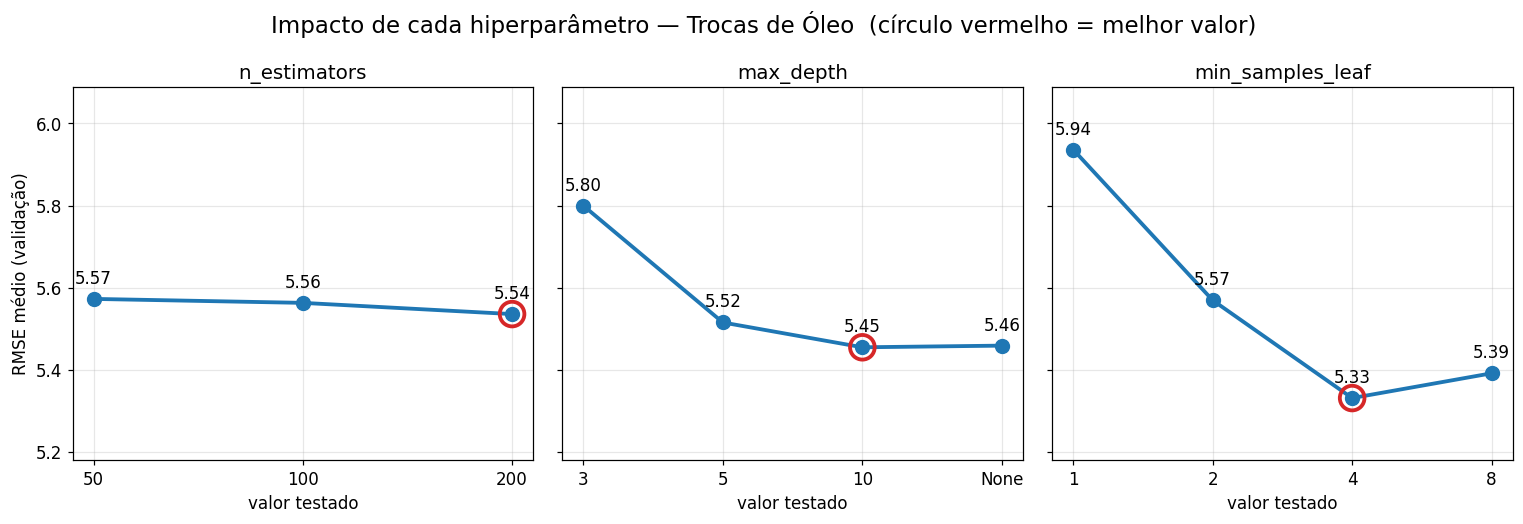

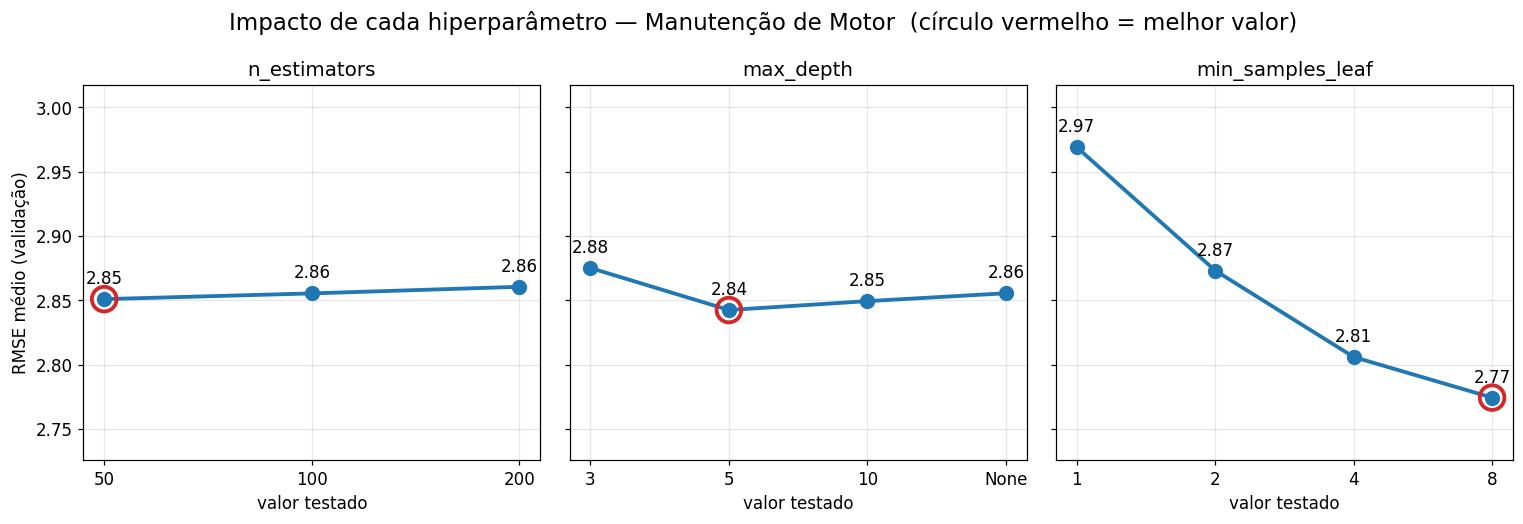

In [10]:
def plotar_impacto_parametros(busca, alvo):
    res = pd.DataFrame(busca.cv_results_)
    res["rmse"] = -res["mean_test_score"]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)   # mesmo eixo Y: compara o peso real de cada parâmetro
    for ax, param in zip(axes, grid.keys()):
        ordem = [str(v) for v in grid[param]]
        chave = res["params"].apply(lambda d: str(d[param]))          # None vira "None"
        serie = res.groupby(chave)["rmse"].mean().reindex(ordem)
        ax.plot(ordem, serie.values, marker="o", markersize=9, lw=2.5, color="#1F77B4")
        for xi, yi in zip(ordem, serie.values):
            ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=11)
        melhor = serie.idxmin()
        ax.scatter([melhor], [serie.min()], s=260, facecolors="none", edgecolors="#D62728", linewidths=2.5, zorder=5)
        ax.margins(y=0.25)
        ax.set_title(param, fontsize=13)
        ax.set_xlabel("valor testado")
    axes[0].set_ylabel("RMSE médio (validação)")
    fig.suptitle(f"Impacto de cada hiperparâmetro — {NOMES[alvo]}  (círculo vermelho = melhor valor)", fontsize=15)
    fig.tight_layout()
    plt.show()


plotar_impacto_parametros(grid_busca["Trocas_Oleo"], "Trocas_Oleo")
plotar_impacto_parametros(grid_busca["Manutencao_Motor"], "Manutencao_Motor")

### 6.2 Ganho em relação ao modelo inicial

O ganho é medido de duas formas: na **validação cruzada do treino** (o que a busca otimizou) e no **conjunto de teste** (dados que o modelo nunca viu).

In [11]:
modelos_tunados = {alvo: grid_busca[alvo].best_estimator_ for alvo in ALVOS}
prev_tunado = {alvo: pd.Series(modelos_tunados[alvo].predict(X_teste), index=teste.index) for alvo in ALVOS}

ganho_grid = {}
for alvo in ALVOS:
    m_ini = avaliar_metricas(teste[alvo], previsoes_iniciais[alvo]["Random Forest"])
    m_tun = avaliar_metricas(teste[alvo], prev_tunado[alvo])
    cv_ini, cv_tun = cv_inicial[alvo]["Random Forest"], -grid_busca[alvo].best_score_

    linhas = {
        "RMSE validação cruzada (treino)": (cv_ini, cv_tun),
        "RMSE teste": (m_ini["RMSE"], m_tun["RMSE"]),
        "MAPE teste (%)": (m_ini["MAPE (%)"], m_tun["MAPE (%)"]),
        "MAE teste": (m_ini["MAE"], m_tun["MAE"]),
    }
    tabela = pd.DataFrame(linhas, index=["RF inicial (default)", "RF tunado (Grid Search)"]).T
    tabela["Redução do erro (%)"] = (tabela.iloc[:, 0] - tabela.iloc[:, 1]) / tabela.iloc[:, 0] * 100
    ganho_grid[alvo] = tabela

    print(f"\n=== {NOMES[alvo]} — RF inicial x RF tunado ===")
    print(tabela.to_string())
    print("best_params_:", grid_busca[alvo].best_params_)


=== Trocas de Óleo — RF inicial x RF tunado ===
                                 RF inicial (default)  RF tunado (Grid Search)  Redução do erro (%)
RMSE validação cruzada (treino)                  5.86                     5.20                11.30
RMSE teste                                       3.81                     3.82                -0.46
MAPE teste (%)                                  13.34                    13.86                -3.91
MAE teste                                        3.04                     3.13                -2.96
best_params_: {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 50}

=== Manutenção de Motor — RF inicial x RF tunado ===
                                 RF inicial (default)  RF tunado (Grid Search)  Redução do erro (%)
RMSE validação cruzada (treino)                  3.00                     2.76                 7.99
RMSE teste                                       2.48                     2.39                 3.48
MAPE teste (%)      

## 7. Sintonia de hiperparâmetros: Random Search e eficiência

**Decisão da equipe:** o Random Search vale a pena quando o servidor é cobrado por tempo de uso ou quando o espaço de busca é grande. Em vez de testar todas as combinações, ele sorteia só `n_iter` delas e costuma chegar perto do melhor resultado do Grid Search, porque poucos hiperparâmetros concentram a maior parte do efeito. Para a oficina, o caminho é explorar com Random Search e só usar o Grid Search para refinar se a redução de erro compensar o custo extra.

Usamos o **mesmo espaço de busca** do Grid, o mesmo `TimeSeriesSplit` e o mesmo critério (RMSE), com `n_iter = 10` (10 das 48 combinações). Cronometramos as duas buscas com `time.perf_counter()`.

In [12]:
N_ITER = 10

random_busca, random_tempo = {}, {}
for alvo in ALVOS:
    busca_r = RandomizedSearchCV(
        estimator=RandomForestRegressor(random_state=SEED),
        param_distributions=grid,
        n_iter=N_ITER,
        cv=TimeSeriesSplit(n_splits=5),
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        random_state=SEED,
    )
    inicio = time.perf_counter()
    busca_r.fit(X_treino, treino[alvo])
    random_tempo[alvo] = time.perf_counter() - inicio
    random_busca[alvo] = busca_r

    print(f"=== {NOMES[alvo]} ===")
    print("best_params_:", busca_r.best_params_)
    print(f"Melhor RMSE na validação cruzada: {-busca_r.best_score_:.3f}  | tempo: {random_tempo[alvo]:.1f} s\n")

=== Trocas de Óleo ===
best_params_: {'n_estimators': 100, 'min_samples_leaf': 4, 'max_depth': None}
Melhor RMSE na validação cruzada: 5.222  | tempo: 6.4 s

=== Manutenção de Motor ===
best_params_: {'n_estimators': 100, 'min_samples_leaf': 4, 'max_depth': None}
Melhor RMSE na validação cruzada: 2.791  | tempo: 6.6 s



=== Trade-off: Grid Search x Random Search ===
Variável                 Trocas de Óleo  Manutenção de Motor
Treinos Grid                     240.00               240.00
Treinos Random                    50.00                50.00
Tempo Grid (s)                    32.33                31.98
Tempo Random (s)                   6.41                 6.58
Random é Nx mais rápido            5.05                 4.86
RMSE validação Grid                5.20                 2.76
RMSE validação Random              5.22                 2.79
RMSE teste Grid                    3.82                 2.39
RMSE teste Random                  3.84                 2.44
MAPE teste Grid (%)               13.86                27.60
MAPE teste Random (%)             13.77                28.40


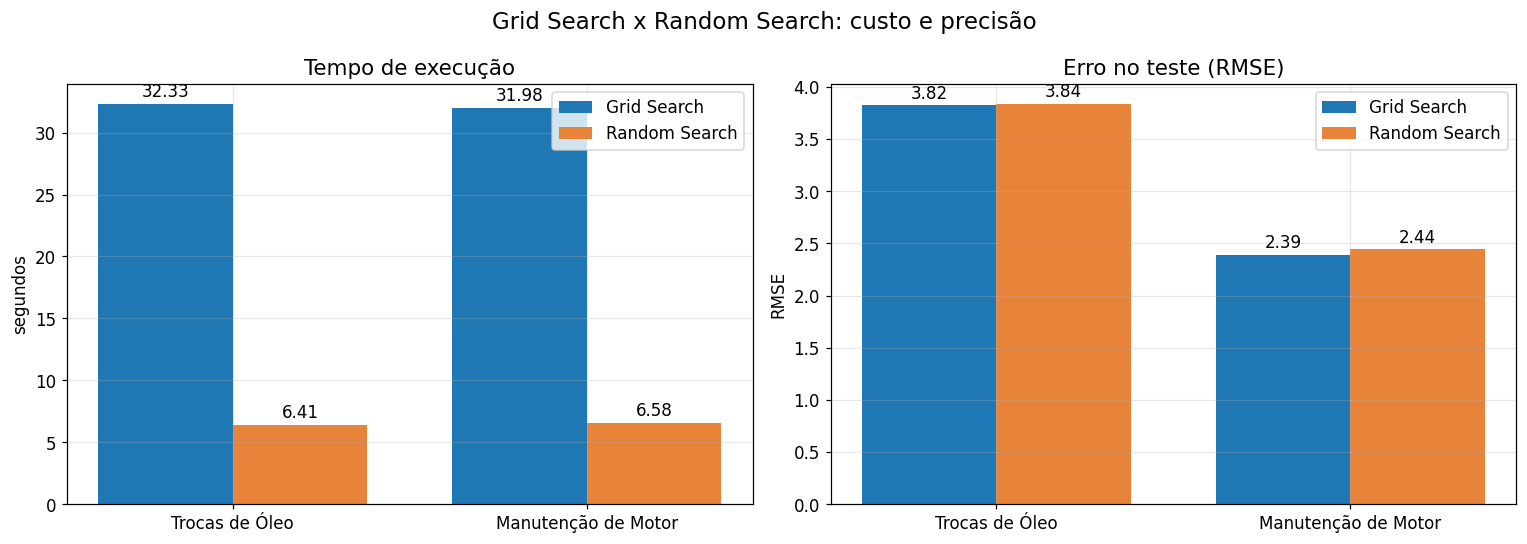

In [13]:
prev_random = {alvo: pd.Series(random_busca[alvo].best_estimator_.predict(X_teste), index=teste.index) for alvo in ALVOS}

linhas = []
for alvo in ALVOS:
    m_g = avaliar_metricas(teste[alvo], prev_tunado[alvo])
    m_r = avaliar_metricas(teste[alvo], prev_random[alvo])
    linhas.append({
        "Variável": NOMES[alvo],
        "Treinos Grid": n_combinacoes * 5, "Treinos Random": N_ITER * 5,
        "Tempo Grid (s)": grid_tempo[alvo], "Tempo Random (s)": random_tempo[alvo],
        "Random é Nx mais rápido": grid_tempo[alvo] / random_tempo[alvo],
        "RMSE validação Grid": -grid_busca[alvo].best_score_, "RMSE validação Random": -random_busca[alvo].best_score_,
        "RMSE teste Grid": m_g["RMSE"], "RMSE teste Random": m_r["RMSE"],
        "MAPE teste Grid (%)": m_g["MAPE (%)"], "MAPE teste Random (%)": m_r["MAPE (%)"],
    })

comparativo_busca = pd.DataFrame(linhas).set_index("Variável")
print("=== Trade-off: Grid Search x Random Search ===")
print(comparativo_busca.T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(ALVOS))
w = 0.38
for ax, (titulo, col_g, col_r, unid) in zip(axes, [
    ("Tempo de execução", "Tempo Grid (s)", "Tempo Random (s)", "segundos"),
    ("Erro no teste (RMSE)", "RMSE teste Grid", "RMSE teste Random", "RMSE"),
]):
    b1 = ax.bar(x - w / 2, comparativo_busca[col_g], w, label="Grid Search", color="#1F77B4")
    b2 = ax.bar(x + w / 2, comparativo_busca[col_r], w, label="Random Search", color="#E8833A")
    ax.bar_label(b1, fmt="%.2f", padding=2)
    ax.bar_label(b2, fmt="%.2f", padding=2)
    ax.set_xticks(x)
    ax.set_xticklabels([NOMES[a] for a in ALVOS])
    ax.set_ylabel(unid)
    ax.set_title(titulo, fontsize=14)
    ax.legend()
fig.suptitle("Grid Search x Random Search: custo e precisão", fontsize=15)
fig.tight_layout()
plt.show()

### 7.1 Conclusão do trade-off (texto gerado a partir dos resultados desta execução)

In [14]:
partes = ["### Trade-off Grid Search × Random Search\n"]
for alvo in ALVOS:
    t_g, t_r = grid_tempo[alvo], random_tempo[alvo]
    r_g = comparativo_busca.loc[NOMES[alvo], "RMSE teste Grid"]
    r_r = comparativo_busca.loc[NOMES[alvo], "RMSE teste Random"]
    dif_pct = (r_r - r_g) / r_g * 100
    if abs(dif_pct) < 3:
        veredito = "praticamente o mesmo erro"
    elif dif_pct > 0:
        veredito = "um erro um pouco maior"
    else:
        veredito = "um erro menor"
    partes.append(
        f"- **{NOMES[alvo]}:** o Grid Search levou **{t_g:.1f} s** e o Random Search **{t_r:.1f} s** "
        f"(**{t_g / t_r:.1f}x mais rápido**, economia de {t_g - t_r:.1f} s). "
        f"O RMSE no teste foi {r_g:.2f} (Grid) contra {r_r:.2f} (Random): diferença de {r_r - r_g:+.2f} "
        f"({dif_pct:+.1f}%), ou seja, {veredito}."
    )
partes.append(
    f"\nO Random Search testou só {N_ITER} das {n_combinacoes} combinações. Para um servidor pago por tempo de uso, "
    "ele entrega o essencial do ganho por uma fração do custo; o Grid Search só compensa quando o espaço de busca é pequeno "
    "ou quando cada décimo de erro tem valor alto para o negócio."
)
display(Markdown("\n".join(partes)))

### Trade-off Grid Search × Random Search

- **Trocas de Óleo:** o Grid Search levou **32.3 s** e o Random Search **6.4 s** (**5.0x mais rápido**, economia de 25.9 s). O RMSE no teste foi 3.82 (Grid) contra 3.84 (Random): diferença de +0.02 (+0.5%), ou seja, praticamente o mesmo erro.
- **Manutenção de Motor:** o Grid Search levou **32.0 s** e o Random Search **6.6 s** (**4.9x mais rápido**, economia de 25.4 s). O RMSE no teste foi 2.39 (Grid) contra 2.44 (Random): diferença de +0.05 (+2.2%), ou seja, praticamente o mesmo erro.

O Random Search testou só 10 das 48 combinações. Para um servidor pago por tempo de uso, ele entrega o essencial do ganho por uma fração do custo; o Grid Search só compensa quando o espaço de busca é pequeno ou quando cada décimo de erro tem valor alto para o negócio.

## 8. Comparação rigorosa: Baseline antigo × ML inicial × ML tunado

**Decisão da equipe (qual métrica explica o ganho ao dono da oficina):** o **MAE**, porque está na mesma unidade do negócio: serviços por dia. O RMSE entra como complemento, porque pesa mais os picos inesperados, que são os que causam falta de peças. O MAPE ajuda a ver o erro em porcentagem, mas exagera quando a demanda do dia é baixa.

O motor de métricas calcula **MAE, RMSE e MAPE ao mesmo tempo** para os três cenários, no mesmo conjunto de teste:

1. **Baseline antigo:** o melhor baseline da OAT 2.
2. **ML inicial:** Random Forest com hiperparâmetros default.
3. **ML tunado:** Random Forest com os melhores hiperparâmetros do Grid Search.

In [15]:
NOME_CENARIOS = {
    "baseline": "Baseline antigo",
    "inicial": "ML inicial (RF default)",
    "tunado": "ML tunado (RF Grid Search)",
}

cenarios = {}
for alvo in ALVOS:
    previsoes = {
        f"{NOME_CENARIOS['baseline']} ({melhor_baseline[alvo]})": baselines[alvo][melhor_baseline[alvo]].loc[teste.index],
        NOME_CENARIOS["inicial"]: previsoes_iniciais[alvo]["Random Forest"],
        NOME_CENARIOS["tunado"]: prev_tunado[alvo],
    }
    cenarios[alvo] = avaliar_cenarios(teste[alvo], previsoes)

    print(f"\n=== {NOMES[alvo]} — conjunto de teste ({teste.index.min().date()} a {teste.index.max().date()}) ===")
    print(cenarios[alvo].to_string())

    base, tun = cenarios[alvo].iloc[0], cenarios[alvo].iloc[2]
    print(f"-> Modelo tunado vs baseline: MAE {(base['MAE'] - tun['MAE']) / base['MAE'] * 100:.1f}% menor | "
          f"RMSE {(base['RMSE'] - tun['RMSE']) / base['RMSE'] * 100:.1f}% menor | "
          f"MAPE de {base['MAPE (%)']:.1f}% para {tun['MAPE (%)']:.1f}%")


=== Trocas de Óleo — conjunto de teste (2025-08-13 a 2025-12-31) ===
                            MAE  RMSE  MAPE (%)
Baseline antigo (Naive)    6.48  8.92     26.80
ML inicial (RF default)    3.04  3.81     13.34
ML tunado (RF Grid Search) 3.13  3.82     13.86
-> Modelo tunado vs baseline: MAE 51.7% menor | RMSE 57.2% menor | MAPE de 26.8% para 13.9%

=== Manutenção de Motor — conjunto de teste (2025-08-13 a 2025-12-31) ===
                                  MAE  RMSE  MAPE (%)
Baseline antigo (Média Móvel 7d) 3.23  3.82     41.05
ML inicial (RF default)          2.05  2.48     28.40
ML tunado (RF Grid Search)       2.00  2.39     27.60
-> Modelo tunado vs baseline: MAE 38.0% menor | RMSE 37.5% menor | MAPE de 41.1% para 27.6%


### 8.1 Plotagem comparativa

Linha **real** × **baseline** × **previsão do modelo tunado**. O painel de cima mostra todo o período de teste; o de baixo dá um zoom nas últimas quatro semanas, para enxergar onde o modelo novo acerta mais.

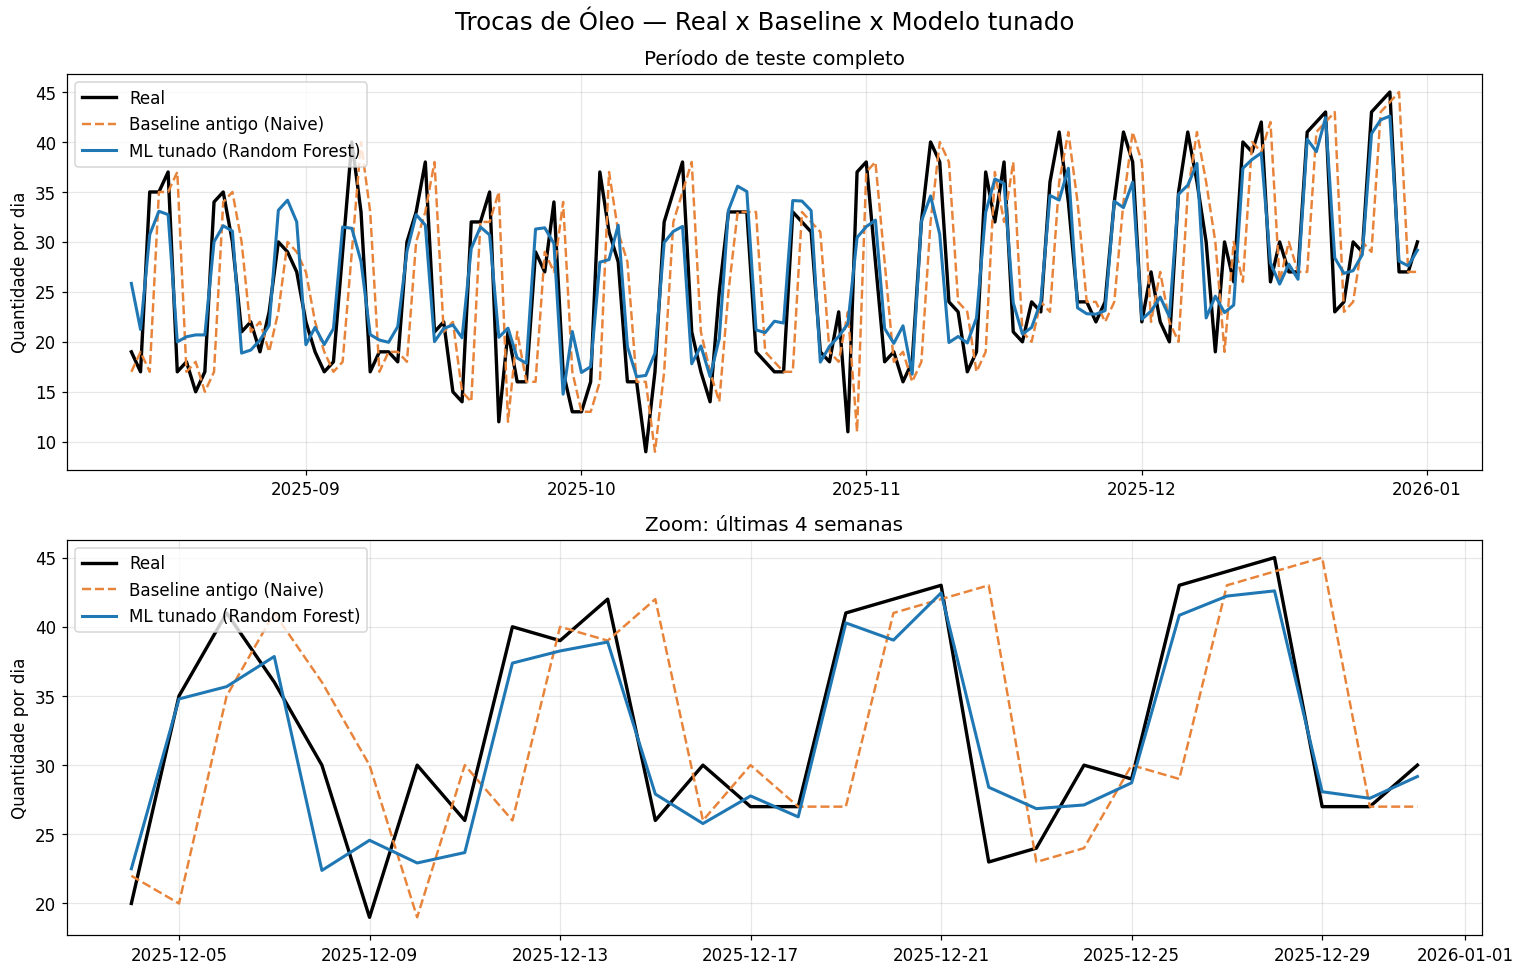

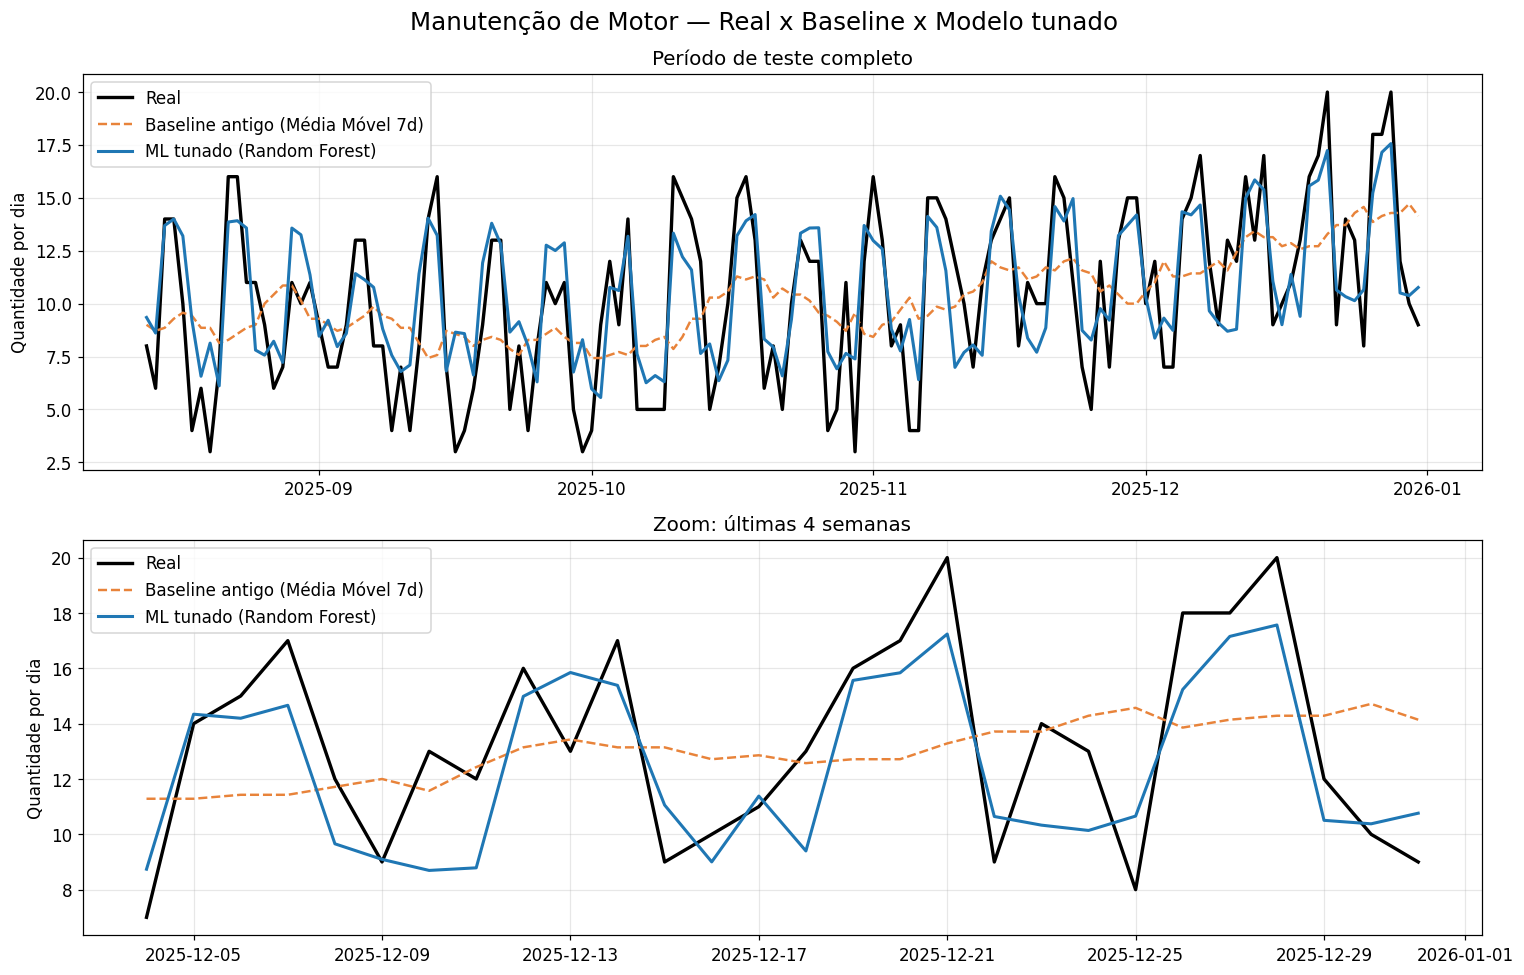

In [16]:
def plotar_comparativo(alvo):
    y = teste[alvo]
    base = baselines[alvo][melhor_baseline[alvo]].loc[teste.index]
    tun = prev_tunado[alvo]

    fig, axes = plt.subplots(2, 1, figsize=(14, 9))
    for ax, ultimos in zip(axes, [None, 28]):
        sl = slice(None) if ultimos is None else slice(-ultimos, None)
        ax.plot(y.index[sl], y.values[sl], color=CORES["Real"], lw=2.2, label="Real")
        ax.plot(base.index[sl], base.values[sl], color=CORES["Baseline"], lw=1.6, ls="--",
                label=f"Baseline antigo ({melhor_baseline[alvo]})")
        ax.plot(tun.index[sl], tun.values[sl], color=CORES["ML tunado"], lw=2.0, label="ML tunado (Random Forest)")
        ax.set_ylabel("Quantidade por dia")
        ax.legend(loc="upper left")
    axes[0].set_title("Período de teste completo", fontsize=13)
    axes[1].set_title("Zoom: últimas 4 semanas", fontsize=13)
    fig.suptitle(f"{NOMES[alvo]} — Real x Baseline x Modelo tunado", fontsize=16)
    fig.tight_layout()
    plt.show()


plotar_comparativo("Trocas_Oleo")
plotar_comparativo("Manutencao_Motor")

### 8.2 Métricas lado a lado

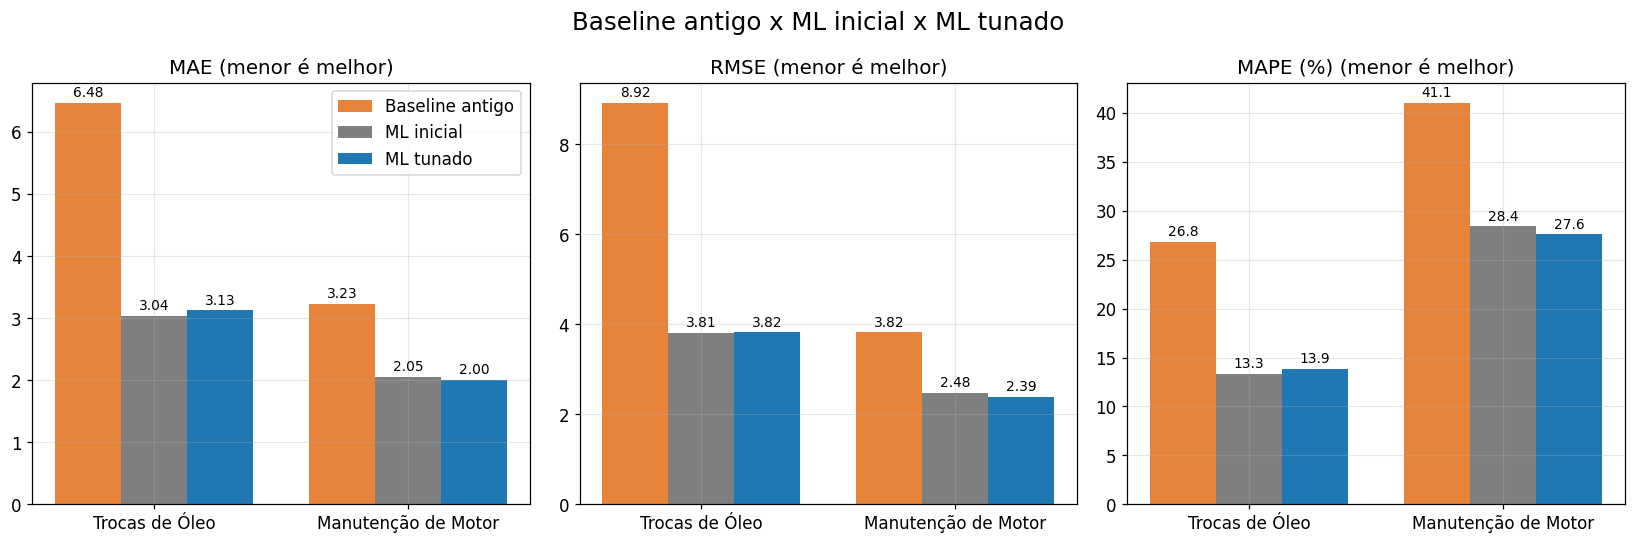

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
cores_cen = ["#E8833A", "#7F7F7F", "#1F77B4"]
x = np.arange(len(ALVOS))
w = 0.26
for ax, metrica in zip(axes, ["MAE", "RMSE", "MAPE (%)"]):
    for i, (rotulo, cor) in enumerate(zip(["Baseline antigo", "ML inicial", "ML tunado"], cores_cen)):
        valores = [cenarios[a][metrica].iloc[i] for a in ALVOS]
        barras = ax.bar(x + (i - 1) * w, valores, w, label=rotulo, color=cor)
        ax.bar_label(barras, fmt="%.1f" if metrica == "MAPE (%)" else "%.2f", padding=2, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([NOMES[a] for a in ALVOS])
    ax.set_title(metrica + " (menor é melhor)", fontsize=13)
axes[0].legend()
fig.suptitle("Baseline antigo x ML inicial x ML tunado", fontsize=16)
fig.tight_layout()
plt.show()

### 8.3 O que o Random Forest aprendeu? (importância das features)

O Random Forest mede quanto cada feature ajudou a reduzir o erro das árvores. Isso ajuda a explicar o modelo para o dono da oficina.

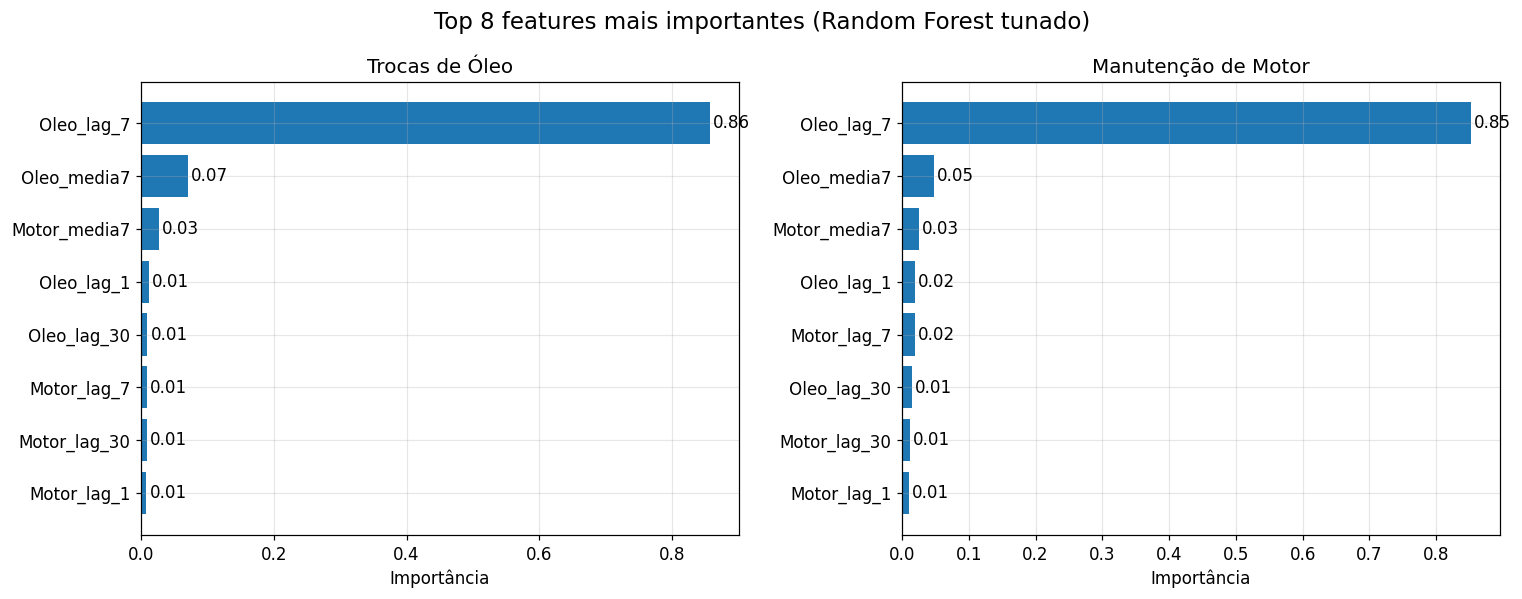

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, alvo in zip(axes, ALVOS):
    imp = pd.Series(modelos_tunados[alvo].feature_importances_, index=FEATURES).sort_values().tail(8)
    barras = ax.barh([n.replace("_rolling_mean_7", "_media7").replace("Manutencao_Motor", "Motor").replace("Trocas_Oleo", "Oleo") for n in imp.index],
                     imp.values, color="#1F77B4")
    ax.bar_label(barras, fmt="%.2f", padding=2)
    ax.set_title(NOMES[alvo], fontsize=13)
    ax.set_xlabel("Importância")
fig.suptitle("Top 8 features mais importantes (Random Forest tunado)", fontsize=15)
fig.tight_layout()
plt.show()

## 9. Conclusão (texto gerado a partir dos resultados desta execução)

In [19]:
def frase_variacao(p):
    return f"redução de {p:.1f}%" if p >= 0 else f"aumento de {abs(p):.1f}%"


partes = ["### Resumo final — MecâniQA, OAT 3\n"]
for alvo in ALVOS:
    base, ini, tun = cenarios[alvo].iloc[0], cenarios[alvo].iloc[1], cenarios[alvo].iloc[2]
    g = ganho_grid[alvo]
    partes.append(
        f"**{NOMES[alvo]}**\n"
        f"- O modelo de ML (mesmo sem tuning) já reduziu o RMSE do baseline de **{base['RMSE']:.2f}** para **{ini['RMSE']:.2f}** "
        f"e o MAPE de **{base['MAPE (%)']:.1f}%** para **{ini['MAPE (%)']:.1f}%**.\n"
        f"- O Grid Search reduziu o RMSE de validação em **{g.loc['RMSE validação cruzada (treino)', 'Redução do erro (%)']:.1f}%**; "
        f"no teste, o RMSE foi de {ini['RMSE']:.2f} para **{tun['RMSE']:.2f}** "
        f"({frase_variacao(g.loc['RMSE teste', 'Redução do erro (%)'])}) e o MAPE de {ini['MAPE (%)']:.1f}% para **{tun['MAPE (%)']:.1f}%** "
        f"({frase_variacao(g.loc['MAPE teste (%)', 'Redução do erro (%)'])}).\n"
        f"- Modelo tunado vs baseline antigo: **{(base['RMSE'] - tun['RMSE']) / base['RMSE'] * 100:.0f}% menos RMSE** "
        f"e **{(base['MAE'] - tun['MAE']) / base['MAE'] * 100:.0f}% menos MAE**.\n"
    )
ganhos_teste = [ganho_grid[a].loc["RMSE teste", "Redução do erro (%)"] for a in ALVOS]
if all(abs(g_) < 5 for g_ in ganhos_teste):
    leitura = ("o tuning melhora o erro de validação (que é o que a busca otimiza), mas no teste o ganho adicional é pequeno, "
               "sinal de que o Random Forest com hiperparâmetros default já estava perto do teto para estes atributos.")
else:
    leitura = "o tuning trouxe ganho relevante também no teste, confirmando que vale a pena sintonizar o modelo."
partes.append(
    "**Leitura honesta dos resultados:** o maior salto de desempenho vem de trocar o baseline por um modelo de Machine Learning "
    "alimentado pelas features temporais; " + leitura + " "
    "O Random Search entrega praticamente o mesmo resultado do Grid Search em uma fração do tempo."
)
partes.append("\n**Próximos passos:** testar features de calendário (dia da semana, feriados) e modelos de séries temporais dedicados.")
display(Markdown("\n".join(partes)))

### Resumo final — MecâniQA, OAT 3

**Trocas de Óleo**
- O modelo de ML (mesmo sem tuning) já reduziu o RMSE do baseline de **8.92** para **3.81** e o MAPE de **26.8%** para **13.3%**.
- O Grid Search reduziu o RMSE de validação em **11.3%**; no teste, o RMSE foi de 3.81 para **3.82** (aumento de 0.5%) e o MAPE de 13.3% para **13.9%** (aumento de 3.9%).
- Modelo tunado vs baseline antigo: **57% menos RMSE** e **52% menos MAE**.

**Manutenção de Motor**
- O modelo de ML (mesmo sem tuning) já reduziu o RMSE do baseline de **3.82** para **2.48** e o MAPE de **41.1%** para **28.4%**.
- O Grid Search reduziu o RMSE de validação em **8.0%**; no teste, o RMSE foi de 2.48 para **2.39** (redução de 3.5%) e o MAPE de 28.4% para **27.6%** (redução de 2.8%).
- Modelo tunado vs baseline antigo: **37% menos RMSE** e **38% menos MAE**.

**Leitura honesta dos resultados:** o maior salto de desempenho vem de trocar o baseline por um modelo de Machine Learning alimentado pelas features temporais; o tuning melhora o erro de validação (que é o que a busca otimiza), mas no teste o ganho adicional é pequeno, sinal de que o Random Forest com hiperparâmetros default já estava perto do teto para estes atributos. O Random Search entrega praticamente o mesmo resultado do Grid Search em uma fração do tempo.

**Próximos passos:** testar features de calendário (dia da semana, feriados) e modelos de séries temporais dedicados.